Image loaded successfully
(810, 720)


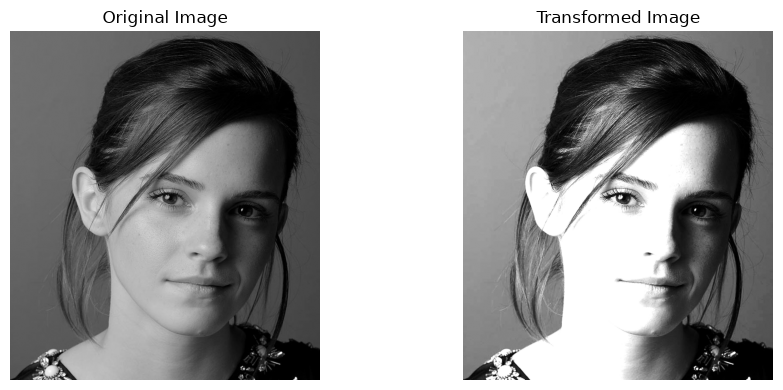

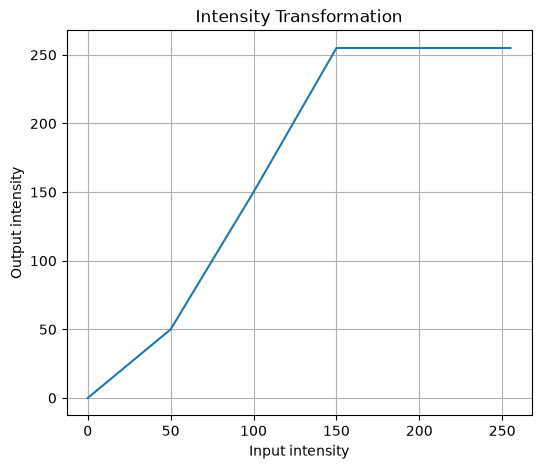

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# Function for intensity transformation
def intensity_transform(im, breakpoints):

    # Create an output image
    output = np.zeros_like(im, dtype=np.uint8)

    # Get the breakpoints
    x1, y1 = breakpoints[0]
    x2, y2 = breakpoints[1]
    x3, y3 = breakpoints[2]
    x4, y4 = breakpoints[3]
    x5, y5 = breakpoints[4]

    # Region 1: 0 - 50
    mask = (im >= x1) & (im < x2)
    output[mask] = ((y2 - y1) / (x2 - x1) *
                    (im[mask] - x1) + y1)

    # Region 2: 50 - 150
    mask = (im >= x2) & (im < x4)
    output[mask] = ((y4 - y2) / (x4 - x2) *
                    (im[mask] - x2) + y2)

    # Region 3: 150 - 255
    mask = im >= x4
    output[mask] = ((y5 - y4) / (x5 - x4) *
                    (im[mask] - x4) + y4)

    return output


# Read the image
#im = cv2.imread(r"C:\Users\YourName\Pictures\image.jpg",cv2.IMREAD_GRAYSCALE)

#im = cv2.imread("your_image.jpg", cv2.IMREAD_GRAYSCALE)
im = cv2.imread(r"C:\Users\PC\OneDrive - University of Moratuwa\Semester 5\Image Processing and Machne Vision\Assignment_1\emma.jpg", cv2.IMREAD_GRAYSCALE)
if im is None:
    print("Image was not loaded. Check the file path.")
else:
    print("Image loaded successfully")
    print(im.shape)

# Breakpoints given in the question
breakpoints = [
    (0, 0),
    (50, 50),
    (100, 150),
    (150, 255),
    (255, 255)
]

# Apply transformation
transformed = intensity_transform(im, breakpoints)


# Display original and transformed images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(im, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(transformed, cmap="gray")
plt.title("Transformed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# Plot the intensity transformation
x = [0, 50, 100, 150, 255]
y = [0, 50, 150, 255, 255]

plt.figure(figsize=(6, 5))
plt.plot(x, y)
plt.xlabel("Input intensity")
plt.ylabel("Output intensity")
plt.title("Intensity Transformation")
plt.grid()
plt.show()